# Nursing Homes Operations in Ireland

## 1. Project Overview

This module focuses on nursing homes in Ireland and their role in providing long-term residential care for older people.

After exploring population growth, functional limitations and Home Support services in the previous modules, I now want to understand the residential side of long-term care.

The main goal is to investigate how nursing home capacity is distributed across Ireland and how it has changed over time.

## 2. Main Research Question

**Is nursing home capacity in Ireland keeping pace with the growing older population?**

To explore this question, I will focus on the number of registered nursing homes, their available capacity and the historical development of long-term care beds.

I will also consider the demographic findings from the first module to provide context for the analysis.

## 3. Data Sources

For this module, I selected two official data sources:

**HIQA — Register of Nursing Homes**

This dataset contains information about registered nursing homes in Ireland, including facility names, locations and maximum occupancy.

It will be used to explore the distribution of registered nursing homes and their capacity.

Source: [HIQA — Nursing Homes](https://www.hiqa.ie/areas-we-work/nursing-homes)

**Department of Health — JQ17: Long-term Care Nursing Beds**

This dataset provides historical information about long-term care nursing beds in Ireland, covering the period from 1987 to 2025.

It will be used to understand how the national number of beds has changed over time.

Source: [Department of Health — JQ17 CSV](https://assets.gov.ie/static/documents/7e1ab8df/JQ17_-_Long-term_care_nursing_beds.csv)

## 4. Initial Analysis Plan

I will begin by exploring the structure and quality of both datasets before deciding which indicators to calculate.

The initial analysis will focus on:

- Number of registered nursing homes.
- Registered capacity across facilities.
- Distribution of nursing homes by county or region, depending on the available information.
- Historical changes in the number of long-term care beds.
- Comparison with the growth of the older population.

## 5. Scope and Limitations

The two datasets provide different types of information.

The HIQA register contains facility-level information, while the JQ17 dataset provides historical national figures.

Therefore, I will first analyse them separately and only combine information if the definitions, periods and level of detail are compatible.

Registered capacity should not automatically be interpreted as the number of occupied beds. Similarly, the number of beds does not represent the total number of people receiving long-term care.

These differences will be considered when interpreting the results.


In [1]:
import pdfplumber
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_nursing_beds = pd.read_csv('../data/raw/JQ17_-_Long-term_care_nursing_beds.csv')

df_nursing_beds.head()

,STATISTIC,Statistic Label,YEAR,Year,BEDTYPE,Bed type,UNIT,VALUE,FLAG,Flag
0,LTCBEDS,Beds in residential long-term care facilities,1987,1987,NURSING,Long-term care nursing bed,Number,9400,NaN,NaN
1,LTCBEDS,Beds in residential long-term care facilities,1988,1988,NURSING,Long-term care nursing bed,Number,9450,NaN,NaN
2,LTCBEDS,Beds in residential long-term care facilities,1989,1989,NURSING,Long-term care nursing bed,Number,11443,NaN,NaN
3,LTCBEDS,Beds in residential long-term care facilities,1990,1990,NURSING,Long-term care nursing bed,Number,11195,NaN,NaN
4,LTCBEDS,Beds in residential long-term care facilities,1991,1991,NURSING,Long-term care nursing bed,Number,11600,NaN,NaN


In [3]:
df_nursing_homes = pd.read_csv('../data/raw/HIQA_Nursing_Homes.csv')

df_nursing_homes.head()

,Centre_ID,Centre_Title,Centre_Address,County,Maximum_Occupancy,Centre_Phone,Person_in_Charge,Person_in_Charge_Phone,Registration_Provider,Registration_Provider_Address,Registration_Provider_Phone,Registration_Date,Registration_Expiry_Date,Expiry_Date_Note,CRO_Registration_Number,Management_Contacts,Registration_Number,Chief_Inspector_Note,Registration_Conditions,URL
0,738,Abbey Haven Care Centre & Nursing Home,"Saint Joseph's Avenue, Boyle, F52 AX24",Roscommon,63,071 967 0111,Breda Casey,071 967 0111,Abbey Haven Care Centre & Nursing Home Limited,"Carrick Road, Boyle, F52 AX24, Roscommon",071 967 0111,01-03-2024,28-02-2027,NaN,675830,Breege Mulryan - 071 967 0111,REG-0038082,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...
1,308,AbbeyBreaffy Nursing Home,"Dublin Road (N5), Castlebar, F23 NY75",Mayo,55,094 902 5029,Selda Susan Babu,094 902 5029,Knegare Nursing Home Holdings Ltd,"Talbot Lodge, 17 Kinsealy Lane, Malahide, K36 ...",01 846 2115,27-12-2025,26-12-2028,NaN,643413,"Denise Steed O Doherty - 086 215 1054, Mairead...",REG-0041188,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...
2,743,Abbeygale House,"Farnogue Residential Unit, Old Hospital Road, ...",Wexford,30,053 915 7821,Julia Miller,053 915 782,Health Service Executive,"Oak House, Millennium Park, Naas, W91 KDC2, Ki...",045 880 400,04-06-2025,03-06-2028,NaN,NaN,NaN,REG-0040306,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...
3,187,Abbeylands Nursing Home,"Carhoo, Kildorrery, P67 NH76",Cork,50,022 250 90,Joys George,022 250 90,Abbeylands Nursing Home & Alzheimer Unit Limited,"Carhoo, Kildorrery, P67 NH76, Cork",022 25 090,31-05-2026,30-05-2029,NaN,448593,NaN,REG-0041818,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...
4,4682,Abbot Close Care Centre,"St. Marys Terrace, Askeaton, V94 F864",Limerick,65,061 601 888,Catherine Lynch (Deputising) for Camilla Pop (...,087 4897030,Abbot Close Nursing Home Ltd,"Market House, Churchtown, Mallow, P51 NH6X, Cork",022 346 93,16-06-2024,15-06-2027,NaN,525869,"Airida Downes - 022 34693, Deirdre Vaughan - 0...",REG-0038665,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...


In [4]:
df_nursing_beds.shape

(39, 10)

In [5]:
df_nursing_beds.info()

<class 'pandas.DataFrame'>
RangeIndex: 39 entries, 0 to 38
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   STATISTIC        39 non-null     str  
 1   Statistic Label  39 non-null     str  
 2   YEAR             39 non-null     int64
 3   Year             39 non-null     int64
 4   BEDTYPE          39 non-null     str  
 5   Bed type         39 non-null     str  
 6   UNIT             39 non-null     str  
 7   VALUE            39 non-null     int64
 8   FLAG             3 non-null      str  
 9   Flag             3 non-null      str  
dtypes: int64(3), str(7)
memory usage: 3.2 KB


In [6]:
df_nursing_beds[['YEAR', 'VALUE', 'FLAG', 'Flag']].tail(10)

,YEAR,VALUE,FLAG,Flag
29,2016,30396,NaN,NaN
30,2017,30732,NaN,NaN
31,2018,31251,NaN,NaN
32,2019,32071,NaN,NaN
33,2020,32104,NaN,NaN
34,2021,31842,NaN,NaN
35,2022,31674,NaN,NaN
36,2023,32155,NaN,NaN
37,2024,32169,NaN,NaN
38,2025,32233,NaN,NaN


In [7]:
df_nursing_beds['FLAG'].value_counts(dropna=False)

FLAG
NaN    36
B       3
Name: count, dtype: int64

In [8]:
df_nursing_beds.loc[df_nursing_beds['FLAG'].notna(), ['YEAR', 'VALUE', 'FLAG', 'Flag']]

,YEAR,VALUE,FLAG,Flag
22,2009,28758,B,Break in series
23,2010,26087,B,Break in series
27,2014,28705,B,Break in series


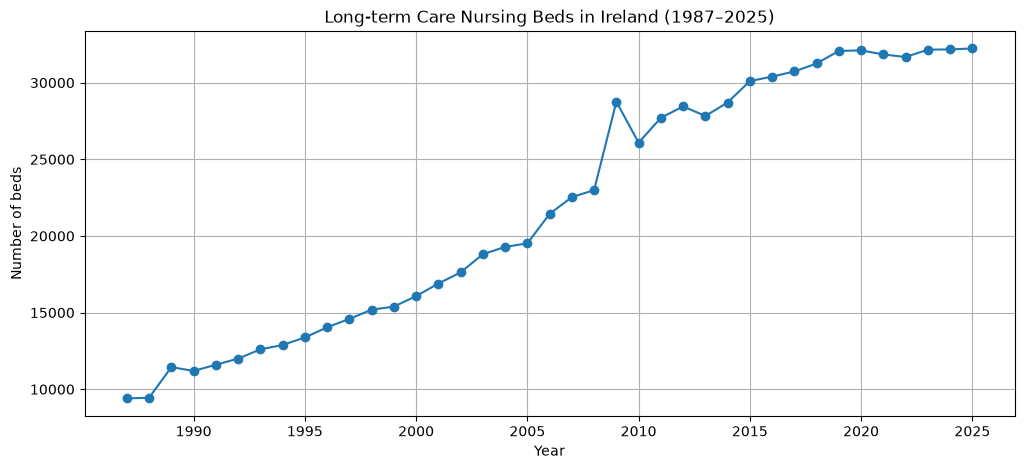

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_nursing_beds['YEAR'],
    df_nursing_beds['VALUE'],
    marker='o'
)

plt.title('Long-term Care Nursing Beds in Ireland (1987–2025)')
plt.xlabel('Year')
plt.ylabel('Number of beds')
plt.grid(True)
plt.show()

In [10]:
df_nursing_beds.columns

Index(['STATISTIC', 'Statistic Label', 'YEAR', 'Year', 'BEDTYPE', 'Bed type',
       'UNIT', 'VALUE', 'FLAG', 'Flag'],
      dtype='str')

In [11]:
df_nursing_beds.columns = (
    df_nursing_beds.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
)

df_nursing_beds.columns

Index(['statistic', 'statistic_label', 'year', 'year', 'bedtype', 'bed_type',
       'unit', 'value', 'flag', 'flag'],
      dtype='str')

In [12]:
df_nursing_beds.columns = [
    'statistic',
    'statistic_label',
    'year_code',
    'year',
    'bedtype',
    'bed_type',
    'unit',
    'value',
    'flag_code',
    'flag_description'
]

df_nursing_beds.info()

<class 'pandas.DataFrame'>
RangeIndex: 39 entries, 0 to 38
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   statistic         39 non-null     str  
 1   statistic_label   39 non-null     str  
 2   year_code         39 non-null     int64
 3   year              39 non-null     int64
 4   bedtype           39 non-null     str  
 5   bed_type          39 non-null     str  
 6   unit              39 non-null     str  
 7   value             39 non-null     int64
 8   flag_code         3 non-null      str  
 9   flag_description  3 non-null      str  
dtypes: int64(3), str(7)
memory usage: 3.2 KB


In [13]:
df_nursing_beds.head()

,statistic,statistic_label,year_code,year,bedtype,bed_type,unit,value,flag_code,flag_description
0,LTCBEDS,Beds in residential long-term care facilities,1987,1987,NURSING,Long-term care nursing bed,Number,9400,NaN,NaN
1,LTCBEDS,Beds in residential long-term care facilities,1988,1988,NURSING,Long-term care nursing bed,Number,9450,NaN,NaN
2,LTCBEDS,Beds in residential long-term care facilities,1989,1989,NURSING,Long-term care nursing bed,Number,11443,NaN,NaN
3,LTCBEDS,Beds in residential long-term care facilities,1990,1990,NURSING,Long-term care nursing bed,Number,11195,NaN,NaN
4,LTCBEDS,Beds in residential long-term care facilities,1991,1991,NURSING,Long-term care nursing bed,Number,11600,NaN,NaN


In [14]:
columns_to_check = [
    'statistic',
    'statistic_label',
    'year_code',
    'bedtype',
    'bed_type',
    'unit'
]

for column in columns_to_check:
    print(f'{column}: {df_nursing_beds[column].nunique()} unique values')

statistic: 1 unique values
statistic_label: 1 unique values
year_code: 39 unique values
bedtype: 1 unique values
bed_type: 1 unique values
unit: 1 unique values


In [15]:
print((df_nursing_beds['year_code'] == df_nursing_beds['year']).all())

True


In [16]:
df_nursing_beds_clean = df_nursing_beds[
    ['year', 'value', 'flag_code', 'flag_description']
].copy()

In [17]:
df_nursing_beds_clean.head()

,year,value,flag_code,flag_description
0,1987,9400,NaN,NaN
1,1988,9450,NaN,NaN
2,1989,11443,NaN,NaN
3,1990,11195,NaN,NaN
4,1991,11600,NaN,NaN


In [18]:
df_nursing_beds_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 39 entries, 0 to 38
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   year              39 non-null     int64
 1   value             39 non-null     int64
 2   flag_code         3 non-null      str  
 3   flag_description  3 non-null      str  
dtypes: int64(2), str(2)
memory usage: 1.3 KB


In [19]:
df_nursing_beds_clean.duplicated().sum()

np.int64(0)

In [20]:
df_nursing_beds_clean['year'].duplicated().sum()

np.int64(0)

In [21]:
df_nursing_beds_clean.isna().sum()

year                 0
value                0
flag_code           36
flag_description    36
dtype: int64

In [22]:
print((df_nursing_beds_clean.isna().mean() * 100).round(2))

year                 0.00
value                0.00
flag_code           92.31
flag_description    92.31
dtype: float64


In [23]:
print('First year: ', df_nursing_beds_clean['year'].min())
print('Last year: ', df_nursing_beds_clean['year'].max())

print('Minimum beds: ', df_nursing_beds_clean['value'].min())
print('Maximum beds: ', df_nursing_beds_clean['value'].max())

First year:  1987
Last year:  2025
Minimum beds:  9400
Maximum beds:  32233


In [24]:
print((df_nursing_beds_clean['value'] > 0).all())

True


### Data Cleaning and Validation

The original dataset contained 39 annual records and 10 columns. During the cleaning process, column names were standardized using snake_case.

Redundant columns were removed because they contained constant information or duplicated the year variable. The final dataset contains four columns: `year`, `value`, `flag_code` and `flag_description`.

The validation confirmed that:

- There are no duplicated rows or years.
- The `year` and `value` columns have no missing values.
- Missing values in the flag columns were preserved because they indicate years without a recorded observation flag.
- The dataset covers the period from 1987 to 2025.
- All bed counts are positive.

Three observations (2009, 2010 and 2014) contain the flag `B` (*Break in series*). These records were retained, but their values will be interpreted with caution when analysing historical trends.

The cleaned dataset is stored in `df_beds_clean`.

## Exploratory Data Analysis

### Nursing Home Bed Capacity (2020–2025)

This section explores the evolution of long-term care nursing bed capacity in Ireland between 2020 and 2025.

The goal is to understand how the number of available nursing home beds changed during this period and compare this trend with the growth of the older population.

In [25]:
df_beds_recent = df_nursing_beds_clean[
    df_nursing_beds_clean['year'].between(2020, 2025)
].copy()

In [26]:
df_beds_recent

,year,value,flag_code,flag_description
33,2020,32104,NaN,NaN
34,2021,31842,NaN,NaN
35,2022,31674,NaN,NaN
36,2023,32155,NaN,NaN
37,2024,32169,NaN,NaN
38,2025,32233,NaN,NaN


In [27]:
initial_beds = df_beds_recent.loc[
    df_beds_recent['year'] == 2020, 'value'
].iloc[0]

final_beds = df_beds_recent.loc[
    df_beds_recent['year'] == 2025, 'value'
].iloc[0]

absolute_change = final_beds - initial_beds

percentage_change = (absolute_change / initial_beds) * 100

print(f'Initial beds (2020): {initial_beds:,}')
print(f'Final beds (2025): {final_beds:,}')
print(f'Absolute change: {absolute_change:,}')
print(f'Percentage change: {percentage_change:.2f}%')

Initial beds (2020): 32,104
Final beds (2025): 32,233
Absolute change: 129
Percentage change: 0.40%


In [28]:
df_beds_recent = df_beds_recent.sort_values('year').copy()

df_beds_recent['absolute_change'] = (
    df_beds_recent['value'].diff()
)

df_beds_recent['percentage_change'] = (
    df_beds_recent['value'].pct_change() * 100
)

df_beds_recent

,year,value,flag_code,flag_description,absolute_change,percentage_change
33,2020,32104,NaN,NaN,NaN,NaN
34,2021,31842,NaN,NaN,-262.0,-0.816098
35,2022,31674,NaN,NaN,-168.0,-0.527605
36,2023,32155,NaN,NaN,481.0,1.518596
37,2024,32169,NaN,NaN,14.0,0.043539
38,2025,32233,NaN,NaN,64.0,0.198949


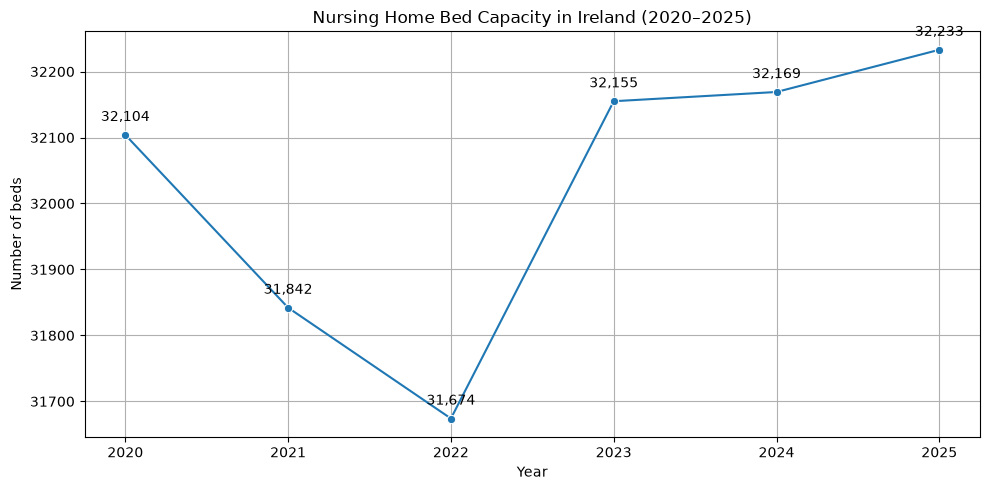

In [29]:
plt.figure(figsize=(10, 5))

ax = sns.lineplot(
    data=df_beds_recent,
    x='year',
    y='value',
    marker='o'
)

for _, row in df_beds_recent.iterrows():
    ax.annotate(
        f"{row['value']:,}",
        (row['year'], row['value']),
        textcoords='offset points',
        xytext=(0, 10),
        ha='center'
    )

plt.title('Nursing Home Bed Capacity in Ireland (2020–2025)')
plt.xlabel('Year')
plt.ylabel('Number of beds')
plt.xticks(df_beds_recent['year'])
plt.grid(True)
plt.tight_layout()
plt.show()

We can see three distinct phases here:

- 2020–2022: a steady drop in capacity, falling from 32,104 to 31,674 beds.

- 2022–2023: a strong rebound, with an increase of 481 beds.

- 2023–2025: slower growth, reaching 32,233 beds.

One quick note: the Y-axis starts around 31,650 instead of zero. While this makes smaller shifts easier to spot, it can also make the changes look more dramatic visually—something worth keeping in mind when looking at overall capacity.

### Did nursing home bed capacity grow at the same pace as the population aged 65 and over between 2020 and 2025?

In [30]:
df_population = pd.read_csv('../data/processed/population_65_plus.csv')

df_population.head()

,year,older_population
0,2020,726.1
1,2021,747.4
2,2022,781.4
3,2023,806.3
4,2024,833.3


In [31]:
print(df_population.dtypes)
print(df_beds_recent.dtypes)

year                  int64
older_population    float64
dtype: object
year                   int64
value                  int64
flag_code                str
flag_description         str
absolute_change      float64
percentage_change    float64
dtype: object


In [32]:
df_capacity_analysis = pd.merge(
    df_beds_recent,
    df_population,
    on='year',
    how='inner'
)

df_capacity_analysis

,year,value,flag_code,flag_description,absolute_change,percentage_change,older_population
0,2020,32104,NaN,NaN,NaN,NaN,726.1
1,2021,31842,NaN,NaN,-262.0,-0.816098,747.4
2,2022,31674,NaN,NaN,-168.0,-0.527605,781.4
3,2023,32155,NaN,NaN,481.0,1.518596,806.3
4,2024,32169,NaN,NaN,14.0,0.043539,833.3
5,2025,32233,NaN,NaN,64.0,0.198949,861.2


In [33]:
df_capacity_analysis['beds_per_1000_older_people'] = (
    df_capacity_analysis['value'] / 
    df_capacity_analysis['older_population']
)

df_capacity_analysis[
    ['year', 'value', 'older_population', 'beds_per_1000_older_people']
]

,year,value,older_population,beds_per_1000_older_people
0,2020,32104,726.1,44.214296
1,2021,31842,747.4,42.603693
2,2022,31674,781.4,40.534937
3,2023,32155,806.3,39.879697
4,2024,32169,833.3,38.604344
5,2025,32233,861.2,37.428007


In [34]:
initial_ratio = df_capacity_analysis.loc[
    df_capacity_analysis['year'] == 2020,
    'beds_per_1000_older_people'
].iloc[0]

final_ratio = df_capacity_analysis.loc[
    df_capacity_analysis['year'] == 2025,
    'beds_per_1000_older_people'
].iloc[0]

ratio_change = final_ratio - initial_ratio

ratio_percentage_change = (
    ratio_change / initial_ratio
) * 100

print(f'Absolute change: {ratio_change:.2f}')
print(f'Percentage change: {ratio_percentage_change:.2f}%')

Absolute change: -6.79
Percentage change: -15.35%


In [35]:
df_capacity_analysis['population_index'] = (
    df_capacity_analysis['older_population'] / 
    df_capacity_analysis.loc[
        df_capacity_analysis['year'] == 2020,
        'older_population'
    ].iloc[0]
) * 100

df_capacity_analysis['beds_index'] = (
    df_capacity_analysis['value'] /
    df_capacity_analysis.loc[
        df_capacity_analysis['year'] == 2020,
        'value'
    ].iloc[0]
) * 100

df_capacity_analysis[
    ['year', 'population_index', 'beds_index']
]

,year,population_index,beds_index
0,2020,100.000000,100.000000
1,2021,102.933480,99.183902
2,2022,107.616031,98.660603
3,2023,111.045311,100.158859
4,2024,114.763807,100.202467
5,2025,118.606253,100.401819


In [36]:
df_index = df_capacity_analysis[
    ['year', 'population_index', 'beds_index']
].melt(
    id_vars='year',
    var_name='indicator',
    value_name='index_value'
)

df_index

,year,indicator,index_value
0,2020,population_index,100.000000
1,2021,population_index,102.933480
2,2022,population_index,107.616031
3,2023,population_index,111.045311
4,2024,population_index,114.763807
5,2025,population_index,118.606253
6,2020,beds_index,100.000000
7,2021,beds_index,99.183902
8,2022,beds_index,98.660603
9,2023,beds_index,100.158859


In [37]:
df_index['indicator'] = (
    df_index['indicator'].replace({
        'population_index': 'Population',
        'beds_index': 'Beds'
    })
)

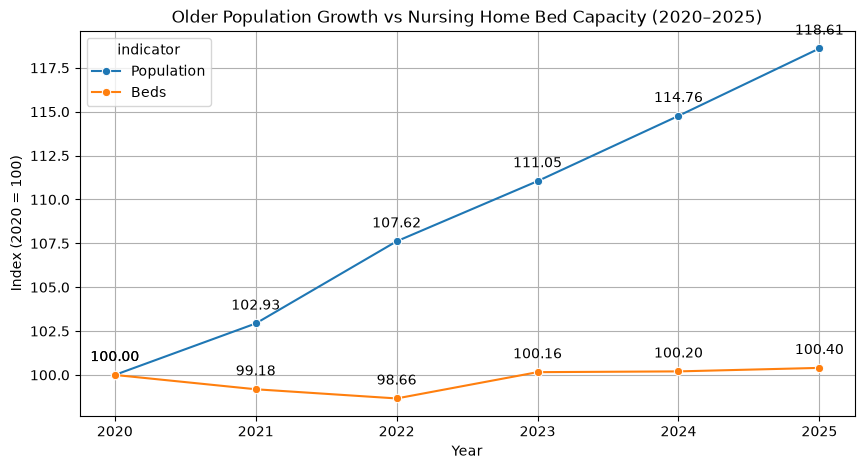

In [38]:
plt.figure(figsize=(10, 5))

ax = sns.lineplot(
    data=df_index,
    x='year',
    y='index_value',
    hue='indicator',
    marker='o'
)

for _, row in df_index.iterrows():
    ax.annotate(
        f"{row['index_value']:,.2f}",
        (row['year'], row['index_value']),
        textcoords='offset points',
        xytext=(0, 10),
        ha='center'
    )

plt.title('Older Population Growth vs Nursing Home Bed Capacity (2020–2025)')
plt.xlabel('Year')
plt.ylabel('Index (2020 = 100)')
plt.xticks(df_index['year'].unique())
plt.grid(True)

plt.show()

### Population Growth vs Nursing Home Bed Capacity (2020–2025)

The comparison shows a clear difference between the growth of Ireland's older population and the number of reported nursing home beds.

Between 2020 and 2025:

- The population aged 65 and over increased by **18.61%**.
- The number of reported nursing home beds increased by only **0.40%**.
- Beds per 1,000 people aged 65+ decreased from **44.21 to 37.43**, a reduction of **15.35%**.

These findings suggest that nursing home bed capacity has not grown at the same pace as the older population.

However, this comparison does not establish whether there is a shortage of nursing home beds. Population aged 65+ is not equivalent to the population requiring residential care, and the number of reported beds does not necessarily represent occupied or immediately available beds.

Further analysis of occupancy, waiting lists and care needs would be necessary to assess actual capacity pressure.

## HIQA Nursing Homes Register Analysis

### What are we going to analyse?

In this section, I will look at the nursing homes registered in Ireland using data from HIQA.

I want to understand how these nursing homes are distributed across the country and how many people they can accommodate.

### Questions I want to answer

- How many nursing homes are registered in Ireland?
- Which counties have more nursing homes?
- Which counties have a higher registered capacity?
- How many people can these nursing homes accommodate in total?
- Are there big differences in capacity between counties?

### Data Source

The data comes from the HIQA Register of Nursing Homes.

The file contains information about each nursing home, such as its name, address, county, maximum occupancy and registration details.

### What will I do?

First, I will check the data to understand its structure and look for missing or duplicated information.

Then, I will clean the columns I need and analyse the number of nursing homes and their registered capacity across different counties.

Finally, I will create charts to make it easier to compare the results.

### A few things to keep in mind

The maximum occupancy recorded in the dataset does not tell us how many residents are currently living in each nursing home.

It also does not mean that all registered places are currently available.

This analysis will focus on registered capacity, not actual occupancy.

In [39]:
df_nursing_homes.shape

(548, 20)

In [40]:
df_nursing_homes.isnull().sum()

Centre_ID                          0
Centre_Title                       0
Centre_Address                     0
County                             0
Maximum_Occupancy                  0
Centre_Phone                       0
Person_in_Charge                  20
Person_in_Charge_Phone            21
Registration_Provider              0
Registration_Provider_Address      0
Registration_Provider_Phone        0
Registration_Date                  0
Registration_Expiry_Date           0
Expiry_Date_Note                 548
CRO_Registration_Number          137
Management_Contacts              202
Registration_Number                0
Chief_Inspector_Note             547
Registration_Conditions            0
URL                                0
dtype: int64

In [41]:
df_nursing_homes.duplicated().sum()

np.int64(0)

In [42]:
key_columns = [
    'Centre_ID',
    'Centre_Title',
    'County',
    'Maximum_Occupancy',
    'Registration_Date',
    'Registration_Expiry_Date'
]

df_nursing_homes[key_columns].isnull().sum()

Centre_ID                   0
Centre_Title                0
County                      0
Maximum_Occupancy           0
Registration_Date           0
Registration_Expiry_Date    0
dtype: int64

In [43]:
df_nursing_homes[key_columns].dtypes

Centre_ID                   int64
Centre_Title                  str
County                        str
Maximum_Occupancy           int64
Registration_Date             str
Registration_Expiry_Date      str
dtype: object

In [44]:
df_nursing_homes.columns = (
    df_nursing_homes.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
)

df_nursing_homes.columns

Index(['centre_id', 'centre_title', 'centre_address', 'county',
       'maximum_occupancy', 'centre_phone', 'person_in_charge',
       'person_in_charge_phone', 'registration_provider',
       'registration_provider_address', 'registration_provider_phone',
       'registration_date', 'registration_expiry_date', 'expiry_date_note',
       'cro_registration_number', 'management_contacts', 'registration_number',
       'chief_inspector_note', 'registration_conditions', 'url'],
      dtype='str')

In [45]:
df_nursing_homes[
    ['registration_date', 'registration_expiry_date']
].head(10)

,registration_date,registration_expiry_date
0,01-03-2024,28-02-2027
1,27-12-2025,26-12-2028
2,04-06-2025,03-06-2028
3,31-05-2026,30-05-2029
4,16-06-2024,15-06-2027
5,06-05-2026,05-05-2029
6,06-12-2023,05-12-2026
7,03-06-2026,02-06-2029
8,05-06-2026,04-06-2029
9,30-09-2024,29-09-2027


In [46]:
date_columns = ['registration_date', 'registration_expiry_date']

for column in date_columns:
    df_nursing_homes[column] = pd.to_datetime(
        df_nursing_homes[column],
        format='%d-%m-%Y',
        errors='coerce'
    )

df_nursing_homes[date_columns].dtypes

registration_date           datetime64[us]
registration_expiry_date    datetime64[us]
dtype: object

In [47]:
df_nursing_homes[date_columns].isnull().sum()

registration_date           0
registration_expiry_date    0
dtype: int64

### Data Cleaning

Before starting the analysis, I checked the dataset to understand its structure and see if there were any data quality issues.

The dataset contains 548 nursing homes and 20 columns. I checked for missing values and duplicate records. There were no duplicated rows.

Some columns had missing information, mainly contact details and management information. Since these fields are not important for the analysis, I decided to keep them as they are and focus on the columns I need.

I also made a few changes to prepare the data:

- Changed all column names to lowercase and used snake_case to make them easier to work with.
- Converted `registration_date` and `registration_expiry_date` from text to datetime format.
- Checked the main columns used in the analysis, such as the centre ID, name, county and maximum occupancy.

The main columns needed for the analysis have no missing values, and both date columns were converted successfully without creating missing dates.

The dataset is now ready for the next steps.

### We want to find out wheter nursing homes have similar capabilities, or if there are significant differences between small and large facilities.

In [48]:
df_nursing_homes['maximum_occupancy'].describe()

count    548.000000
mean      59.600365
std       32.238244
min       11.000000
25%       36.000000
50%       51.000000
75%       71.000000
max      190.000000
Name: maximum_occupancy, dtype: float64

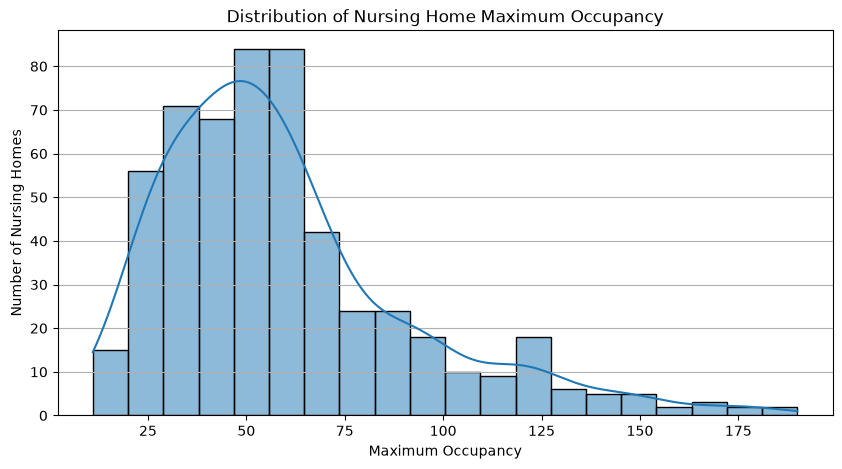

In [49]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=df_nursing_homes,
    x='maximum_occupancy',
    bins=20,
    kde=True
)

plt.title('Distribution of Nursing Home Maximum Occupancy')
plt.xlabel('Maximum Occupancy')
plt.ylabel('Number of Nursing Homes')
plt.grid(axis='y')

plt.show()

#### Explaining the chart

- Most nursing homes have between roughly 30 and 65 beds.
- The distribution peaks around 50–60 beds.
- Fewer facilities have a capacity of over 100.
- Only a small number reach capacities between 150 and 190.

This explains why the average (59.6) is higher than the median (51): a handful of larger facilities pull the average up. Overall, most registered nursing homes are small to mid-sized, while a smaller group operates on a much larger scale.

This matters because the number of facilities alone doesn't tell the whole story—a county with just a few nursing homes can still have a high total capacity if those facilities are large.

### Calculate the total capacity - Let's find out how many people the 548 establishments can accommodate, based on their recorded maximum capacity. 

In [50]:
total_capacity = df_nursing_homes['maximum_occupancy'].sum()

print(f"Total registered capacity: {total_capacity:,}")

Total registered capacity: 32,661


In [51]:
average_capacity = df_nursing_homes['maximum_occupancy'].mean()

print(f"Average capacity per nursing home: {average_capacity:.2f}")

Average capacity per nursing home: 59.60


In [52]:
df_nursing_homes['county'].nunique()

26

In [53]:
sorted(df_nursing_homes['county'].unique())

['Carlow',
 'Cavan',
 'Clare',
 'Cork',
 'Donegal',
 'Dublin',
 'Galway',
 'Kerry',
 'Kildare',
 'Kilkenny',
 'Laois',
 'Leitrim',
 'Limerick',
 'Longford',
 'Louth',
 'Mayo',
 'Meath',
 'Monaghan',
 'Offaly',
 'Roscommon',
 'Sligo',
 'Tipperary',
 'Waterford',
 'Westmeath',
 'Wexford',
 'Wicklow']

### Group the data by county

We want to determine three things for each county: 
1. How many nursing homes are registered?
2. What is the total registered maximum capacity?
3. What is the average capacity per facility?

In [54]:
df_county = (
    df_nursing_homes
    .groupby('county')
    .agg(
        nursing_homes=('centre_id', 'count'),
        total_capacity=('maximum_occupancy', 'sum'),
        average_capacity=('maximum_occupancy', 'mean')
    )
    .reset_index()
)

df_county.head()

,county,nursing_homes,total_capacity,average_capacity
0,Carlow,8,376,47.000000
1,Cavan,10,487,48.700000
2,Clare,16,883,55.187500
3,Cork,70,3797,54.242857
4,Donegal,21,918,43.714286


In [55]:
df_county_sorted = df_county.sort_values(
    by='total_capacity',
    ascending=False
)

df_county_sorted.head(5)

,county,nursing_homes,total_capacity,average_capacity
5,Dublin,106,8596,81.094340
3,Cork,70,3797,54.242857
6,Galway,38,1738,45.736842
8,Kildare,22,1534,69.727273
16,Meath,20,1328,66.400000


In [56]:
df_county_sorted.tail(5)

,county,nursing_homes,total_capacity,average_capacity
0,Carlow,8,376,47.000000
17,Monaghan,5,364,72.800000
10,Laois,5,288,57.600000
13,Longford,4,286,71.500000
11,Leitrim,6,239,39.833333


### Investigate the concentration of capacity

I want to find out how much of the total registered national capacity is concentrated in Dublin. First, let's calculate the percentage share of each county in the total capacity.

In [57]:
df_county_sorted['capacity_share'] = (
    df_county_sorted['total_capacity'] / 
    df_county_sorted['total_capacity'].sum()
) * 100

df_county_sorted[
    ['county', 'total_capacity', 'capacity_share']
].head(10)

,county,total_capacity,capacity_share
5,Dublin,8596,26.318851
3,Cork,3797,11.625486
6,Galway,1738,5.321331
8,Kildare,1534,4.696733
16,Meath,1328,4.066011
12,Limerick,1317,4.032332
21,Tipperary,1274,3.900677
25,Wicklow,1195,3.658798
24,Wexford,1107,3.389363
15,Mayo,1096,3.355684


In [58]:
df_county_sorted['capacity_share'].sum()

np.float64(99.99999999999999)

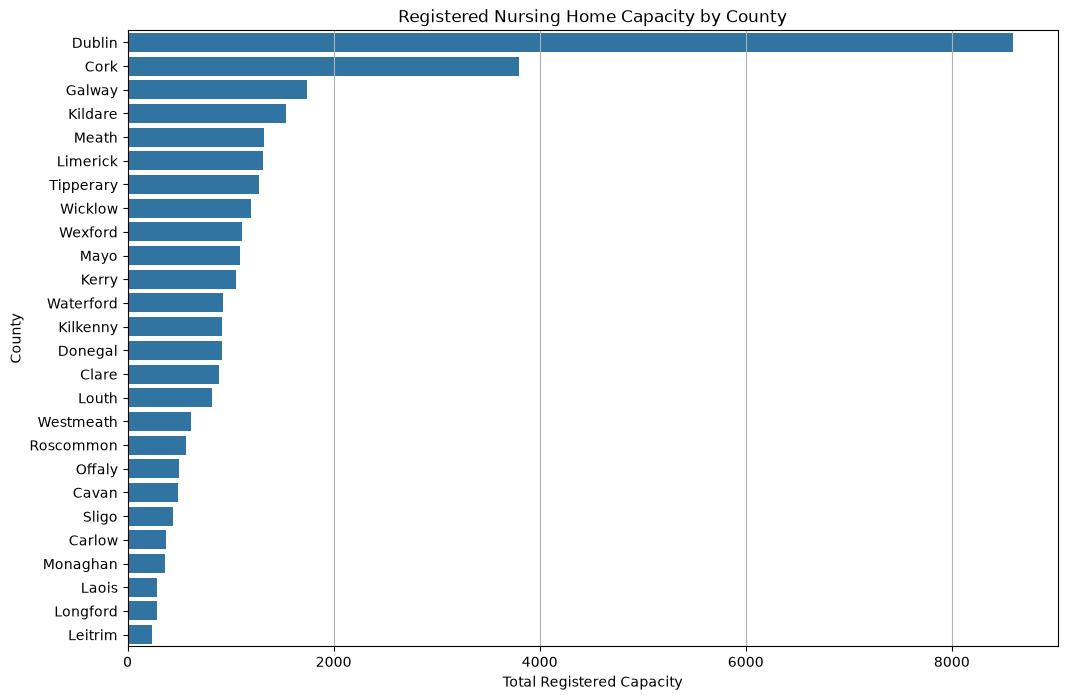

In [59]:
plt.figure(figsize=(12,8))

sns.barplot(
    data=df_county_sorted,
    x='total_capacity',
    y='county'
)

plt.title('Registered Nursing Home Capacity by County')
plt.xlabel('Total Registered Capacity')
plt.ylabel('County')
plt.grid(axis='x')
plt.show()

Here is what stands out from the data:

1. Dublin leads by a wide margin: It has 8,596 registered beds, which is about 26.3% of the entire country's capacity.
2. Cork is a distant second: With 3,797 beds, it has less than half of what Dublin offers.
3. There is a big drop-off after the top thwo: Galway comes in third with just 1,738 beds.
4. Leitrim has the lowest capacity: Only 239 beds registered.

Overall, Dublin and Cork really dominate the landscape compared to the rest of the counties.

### Population by County – CSO Data

#### What are we going to analyse?

In this section, I will use population data from the Central Statistics Office (CSO) to understand how the population aged 65 and over is distributed across Ireland.

The idea is to compare the number of people aged 65+ in each county with the registered nursing home capacity in the same area.

#### Why is this important?

Looking only at the number of nursing homes or registered places does not tell us much about whether the capacity is proportional to the local population.

For example, a county may have more nursing home places simply because it has a larger population.

By comparing registered capacity with the older population, I can get a better picture of how nursing home capacity is distributed across the country.

#### Data Source

The data comes from the CSO (Central Statistics Office), table PEA08 – Estimated Population by Age Group, Sex, County and Year.

The dataset includes population estimates by county, age group, sex and year. For this analysis, I will focus on:

- People aged 65 and over.
- Both sexes.
- All 26 counties.
- The period from 2020 to 2025.

The population figures are provided in thousands.

#### What will I do?

First, I will check and clean the dataset.

Then, I will combine the age groups from 65 years onwards to calculate the total population aged 65+ in each county.

After that, I will compare these figures with the registered nursing home capacity from the HIQA dataset.

I will also calculate the number of registered nursing home places per 1,000 people aged 65+ in each county.

#### A few things to keep in mind

The population aged 65 and over does not represent the number of people who actually need nursing home care.

Also, registered capacity does not tell us how many places are currently occupied or available.

This comparison will help me understand how capacity is distributed in relation to the older population, but it will not measure actual demand or prove that a county has enough nursing home places.

In [60]:
df_population_county = pd.read_csv('../data/raw/PEA08.20261125T211151.csv')

df_population_county.head()

,Statistic Label,Year,Age Group,Sex,County,UNIT,VALUE
0,Estimated Population (Persons in April),2020,65 - 69 years,Both sexes,Ireland,Thousand,228.7
1,Estimated Population (Persons in April),2020,65 - 69 years,Both sexes,Co. Clare,Thousand,6.4
2,Estimated Population (Persons in April),2020,65 - 69 years,Both sexes,Co. Cork,Thousand,26.1
3,Estimated Population (Persons in April),2020,65 - 69 years,Both sexes,Co. Cavan,Thousand,3.7
4,Estimated Population (Persons in April),2020,65 - 69 years,Both sexes,Co. Carlow,Thousand,2.8


In [61]:
df_population_county.columns = (
    df_population_county.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
)

df_population_county.head()

,statistic_label,year,age_group,sex,county,unit,value
0,Estimated Population (Persons in April),2020,65 - 69 years,Both sexes,Ireland,Thousand,228.7
1,Estimated Population (Persons in April),2020,65 - 69 years,Both sexes,Co. Clare,Thousand,6.4
2,Estimated Population (Persons in April),2020,65 - 69 years,Both sexes,Co. Cork,Thousand,26.1
3,Estimated Population (Persons in April),2020,65 - 69 years,Both sexes,Co. Cavan,Thousand,3.7
4,Estimated Population (Persons in April),2020,65 - 69 years,Both sexes,Co. Carlow,Thousand,2.8


In [62]:
df_population_county['age_group'].unique()

<StringArray>
[    '65 - 69 years',     '70 - 74 years',     '75 - 79 years',
     '80 - 84 years', '85 years and over']
Length: 5, dtype: str

In [63]:
sorted(df_population_county['county'].unique())

['Co. Carlow',
 'Co. Cavan',
 'Co. Clare',
 'Co. Cork',
 'Co. Donegal',
 'Co. Dublin',
 'Co. Galway',
 'Co. Kerry',
 'Co. Kildare',
 'Co. Kilkenny',
 'Co. Laois',
 'Co. Leitrim',
 'Co. Limerick',
 'Co. Longford',
 'Co. Louth',
 'Co. Mayo',
 'Co. Meath',
 'Co. Monaghan',
 'Co. Offaly',
 'Co. Roscommon',
 'Co. Sligo',
 'Co. Tipperary',
 'Co. Waterford',
 'Co. Westmeath',
 'Co. Wexford',
 'Co. Wicklow',
 'Ireland']

In [64]:
df_population_county['county'] = (
    df_population_county['county']
    .str.replace('Co. ', '', regex=False)
)

sorted(df_population_county['county'].unique())

['Carlow',
 'Cavan',
 'Clare',
 'Cork',
 'Donegal',
 'Dublin',
 'Galway',
 'Ireland',
 'Kerry',
 'Kildare',
 'Kilkenny',
 'Laois',
 'Leitrim',
 'Limerick',
 'Longford',
 'Louth',
 'Mayo',
 'Meath',
 'Monaghan',
 'Offaly',
 'Roscommon',
 'Sligo',
 'Tipperary',
 'Waterford',
 'Westmeath',
 'Wexford',
 'Wicklow']

In [65]:
df_population_county = df_population_county[df_population_county['county'] != 'Ireland'].copy()

In [66]:
df_population_county['county'].nunique()

26

In [67]:
df_population_65_plus = (
    df_population_county
    .groupby(['county', 'year'])
    .agg(
        population_65_plus=('value', 'sum')
    )
    .reset_index()
)

df_population_65_plus.head(10)

,county,year,population_65_plus
0,Carlow,2020,8.7
1,Carlow,2021,9.0
2,Carlow,2022,9.3
3,Carlow,2023,9.7
4,Carlow,2024,10.1
5,Carlow,2025,10.4
6,Cavan,2020,11.9
7,Cavan,2021,12.4
8,Cavan,2022,12.7
9,Cavan,2023,13.1


In [68]:
df_population_65_plus.shape

(156, 3)

In [69]:
df_population_65_plus.duplicated(subset=['county', 'year']).sum()

np.int64(0)

In [70]:
df_population_65_plus.isna().sum()

county                0
year                  0
population_65_plus    0
dtype: int64

### Make a comparison com Nursing Homes

In [71]:
df_population_2025 = df_population_65_plus[
    df_population_65_plus['year'] == 2025
].copy()

df_population_2025.shape

(26, 3)

In [72]:
df_county_analysis = pd.merge(
    df_county,
    df_population_2025,
    on='county',
    how='inner',
    validate='one_to_one'
)

df_county_analysis.head()


,county,nursing_homes,total_capacity,average_capacity,year,population_65_plus
0,Carlow,8,376,47.000000,2025,10.4
1,Cavan,10,487,48.700000,2025,13.8
2,Clare,16,883,55.187500,2025,23.7
3,Cork,70,3797,54.242857,2025,99.9
4,Donegal,21,918,43.714286,2025,31.9


In [73]:
df_county_analysis['capacity_per_1000_older_people'] = (
    df_county_analysis['total_capacity'] / 
    df_county_analysis['population_65_plus']
)

df_county_analysis.sort_values(
    by='capacity_per_1000_older_people',
    ascending=False
).head(10)

,county,nursing_homes,total_capacity,average_capacity,year,population_65_plus,capacity_per_1000_older_people
9,Kilkenny,18,919,51.055556,2025,19.2,47.864583
25,Wicklow,19,1195,62.894737,2025,26.2,45.610687
8,Kildare,22,1534,69.727273,2025,34.3,44.723032
16,Meath,20,1328,66.400000,2025,30.8,43.116883
22,Waterford,13,923,71.000000,2025,23.1,39.956710
19,Roscommon,11,563,51.181818,2025,14.2,39.647887
5,Dublin,106,8596,81.094340,2025,218.5,39.340961
21,Tipperary,30,1274,42.466667,2025,32.4,39.320988
23,Westmeath,10,612,61.200000,2025,15.8,38.734177
3,Cork,70,3797,54.242857,2025,99.9,38.008008


In [74]:
df_county_analysis.sort_values(
    by='capacity_per_1000_older_people',
    ascending=True
).head(10)

,county,nursing_homes,total_capacity,average_capacity,year,population_65_plus,capacity_per_1000_older_people
10,Laois,5,288,57.600000,2025,13.7,21.021898
4,Donegal,21,918,43.714286,2025,31.9,28.777429
17,Monaghan,5,364,72.800000,2025,11.5,31.652174
7,Kerry,22,1054,47.909091,2025,32.5,32.430769
20,Sligo,8,445,55.625000,2025,13.6,32.720588
11,Leitrim,6,239,39.833333,2025,7.0,34.142857
18,Offaly,8,498,62.250000,2025,14.2,35.070423
12,Limerick,25,1317,52.680000,2025,37.4,35.213904
1,Cavan,10,487,48.700000,2025,13.8,35.289855
0,Carlow,8,376,47.000000,2025,10.4,36.153846


In [75]:
df_county_analysis['capacity_per_1000_older_people'].describe()

count    26.000000
mean     36.922875
std       5.403827
min      21.021898
25%      35.106293
50%      36.842963
75%      39.335968
max      47.864583
Name: capacity_per_1000_older_people, dtype: float64

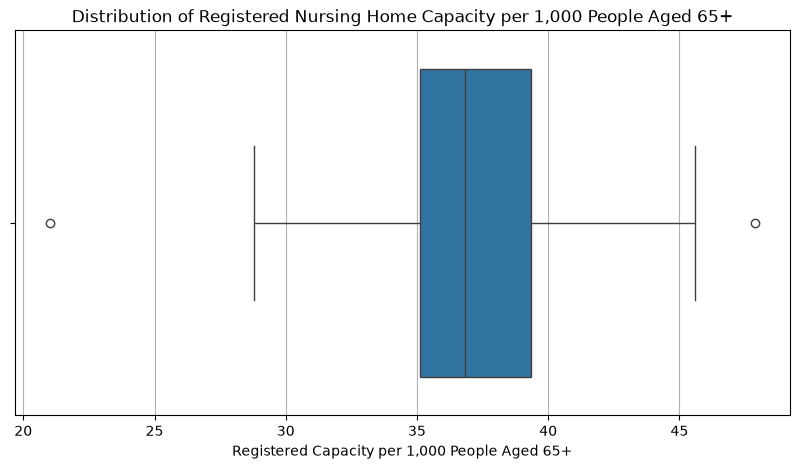

In [76]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df_county_analysis,
    x='capacity_per_1000_older_people'
)

plt.title('Distribution of Registered Nursing Home Capacity per 1,000 People Aged 65+')
plt.xlabel('Registered Capacity per 1,000 People Aged 65+')
plt.grid(axis='x')
plt.show()

How to read this chart: 

- Median: Roughly 36.84 beds per 1.000 people aged 65+ (shown by the line inside the box).
- Middle 50% of counties: Most fall within a tight range between 35.11 and 39.34 beds. 
- Laois: Shows up as a potencial low outlier at 21.02.
- Kilkenny: Stands out as a potential high outlier at 47.86.

The two circles represent data points that fall outside the boxplot's whiskers. This doesn't mean they are data errors-just unusual values worth looking into more closely. 

In [77]:
national_capacity_per_1000 = (
    df_county_analysis['total_capacity'].sum() / 
    df_county_analysis['population_65_plus'].sum()
)

national_capacity_per_1000

np.float64(37.93379790940766)

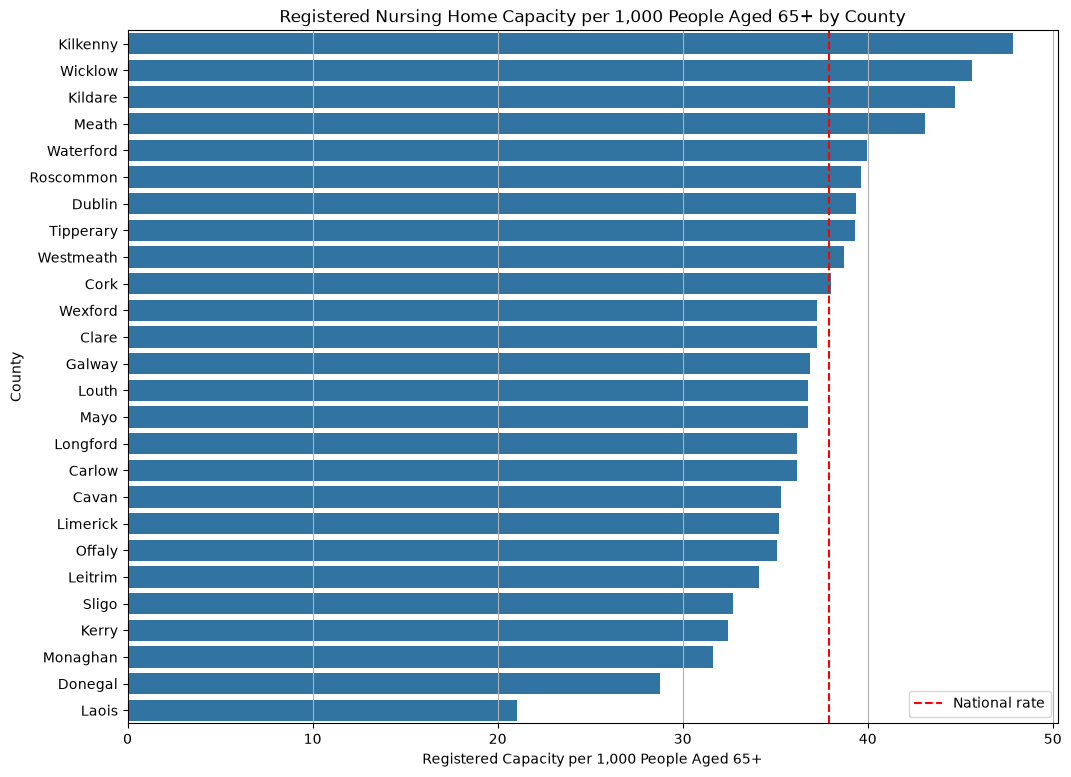

In [78]:
plt.figure(figsize=(12, 9))

sns.barplot(
    data=df_county_analysis.sort_values(
        'capacity_per_1000_older_people',
        ascending=False
    ),
    x='capacity_per_1000_older_people',
    y='county'
)

plt.axvline(
    national_capacity_per_1000,
    color='red',
    linestyle='--',
    label='National rate'
)

plt.title('Registered Nursing Home Capacity per 1,000 People Aged 65+ by County')
plt.xlabel('Registered Capacity per 1,000 People Aged 65+')
plt.ylabel('County')
plt.legend()
plt.grid(axis='x')
plt.show()

The counties above the national benchmark are:

- Kilkenny
- Wicklow
- Kildare
- Meath
- Waterford
- Roscommon
- Dublin
- Tipperary
- Westmeath

Below the national rate
The remaining 17 counties fall below the benchmark. The most notable ones are:

- Laois: roughly 21.02
- Donegal: roughly 28.78
- Monaghan: roughly 31.65

2. A few interesting takeaways

- Dublin isn't as far ahead as it first seemed: In the first chart, Dublin had the highest overall capacity with 8,596 beds. However, once we factor in its older population, its rate sits at 39.34—just slightly above the national benchmark.

- Kilkenny and Wicklow take the top spots: Both have a proportionally higher registered capacity relative to their 65+ population.

- Laois stands out on the low end: Its rate is significantly below the national benchmark. While this is definitely worth looking into, it doesn't automatically mean there is an actual bed shortage.

In [79]:
above_national = (
    df_county_analysis['capacity_per_1000_older_people'] 
    > national_capacity_per_1000
).sum()

below_national = (
    df_county_analysis['capacity_per_1000_older_people']
    < national_capacity_per_1000
).sum()

print('Above national rate:', above_national)
print('Below national rate:', below_national)

Above national rate: 10
Below national rate: 16


In [80]:
df_county_analysis['difference_from_national'] = (
    df_county_analysis['capacity_per_1000_older_people']
    - national_capacity_per_1000
)

df_county_analysis.sort_values(
    by='difference_from_national',
    ascending=False
)

,county,nursing_homes,total_capacity,average_capacity,year,population_65_plus,capacity_per_1000_older_people,difference_from_national
9,Kilkenny,18,919,51.055556,2025,19.2,47.864583,9.930785
25,Wicklow,19,1195,62.894737,2025,26.2,45.610687,7.676889
8,Kildare,22,1534,69.727273,2025,34.3,44.723032,6.789234
16,Meath,20,1328,66.400000,2025,30.8,43.116883,5.183085
22,Waterford,13,923,71.000000,2025,23.1,39.956710,2.022912
19,Roscommon,11,563,51.181818,2025,14.2,39.647887,1.714089
5,Dublin,106,8596,81.094340,2025,218.5,39.340961,1.407163
21,Tipperary,30,1274,42.466667,2025,32.4,39.320988,1.387190
23,Westmeath,10,612,61.200000,2025,15.8,38.734177,0.800379
3,Cork,70,3797,54.242857,2025,99.9,38.008008,0.074210


In [81]:
df_county_analysis.sort_values(
    by='difference_from_national',
    ascending=True
).head()

,county,nursing_homes,total_capacity,average_capacity,year,population_65_plus,capacity_per_1000_older_people,difference_from_national
10,Laois,5,288,57.600000,2025,13.7,21.021898,-16.911900
4,Donegal,21,918,43.714286,2025,31.9,28.777429,-9.156368
17,Monaghan,5,364,72.800000,2025,11.5,31.652174,-6.281624
7,Kerry,22,1054,47.909091,2025,32.5,32.430769,-5.503029
20,Sligo,8,445,55.625000,2025,13.6,32.720588,-5.213210


### Nursing Home Capacity vs Older Population by County (2025)

#### What did I want to understand?

After analysing the number of nursing homes and their registered capacity across Ireland, I wanted to understand how this capacity compares with the older population in each county.

Looking at the total number of registered places alone does not give us the full picture, as counties have different population sizes.

To make this comparison, I combined the HIQA nursing home register with population estimates from the CSO (PEA08).

#### Methodology

I used the 2025 population estimates for people aged 65 and over, combining the five age groups from 65–69 to 85 years and over.

I then compared the total registered nursing home capacity in each county with its population aged 65+.

The main indicator used was registered nursing home places per 1,000 people aged 65+.

The national rate was calculated using the total registered capacity and the total population aged 65+ across all 26 counties.

#### Key Findings

The national rate was approximately **37.93 registered places per 1,000 people aged 65+**.

Out of the 26 counties:

- 10 counties were above the national rate.
- 16 counties were below the national rate.

Kilkenny had the highest rate, with 47.86 registered places per 1,000 people aged 65+, followed by Wicklow (45.61) and Kildare (44.72).

Laois had the lowest rate, with 21.02, followed by Donegal (28.78) and Monaghan (31.65).

Dublin had the highest total registered capacity, with 8,596 places. However, when population size was taken into account, its rate was 39.34, only slightly above the national figure.

Cork also had a rate close to the national figure, with 38.01 registered places per 1,000 people aged 65+.

The comparison highlights differences in how registered nursing home capacity is distributed across counties in relation to their older populations.

#### Limitations

There are some important limitations to consider:

- The population aged 65+ does not represent the number of people who actually need nursing home care.
- Registered maximum occupancy does not indicate how many places are currently occupied or available.
- The comparison does not include waiting lists, admission rates or actual occupancy.
- The HIQA register and CSO population estimates may refer to slightly different reference dates.
- The indicator does not account for differences in health conditions, functional limitations or preferences for home care.

Therefore, the results should be interpreted as a comparison of registered capacity relative to the older population, rather than a measure of actual care availability or unmet demand.

#### Conclusion

The analysis shows that registered nursing home capacity varies across Irish counties when compared with the population aged 65 and over.

While some counties have a higher number of registered places relative to their older population, others are considerably below the national rate.

These differences highlight the importance of looking beyond total capacity when analysing long-term care provision in Ireland.

Further information on occupancy, waiting lists and care needs would be needed to understand whether these differences reflect gaps in access to residential care.

### Calculate population growth by county

In [82]:
df_population_2020 = df_population_65_plus[
    df_population_65_plus['year'] == 2020
].copy()

df_population_2025 = df_population_65_plus[
    df_population_65_plus['year'] == 2025
].copy()

df_population_2020.head()

,county,year,population_65_plus
0,Carlow,2020,8.7
6,Cavan,2020,11.9
12,Clare,2020,20.3
18,Cork,2020,83.4
24,Donegal,2020,27.9


In [83]:
df_population_growth = pd.merge(
    df_population_2020,
    df_population_2025,
    on='county',
    how='inner',
    suffixes=('_2020', '_2025'),
    validate='one_to_one'
)

df_population_growth.head()

,county,year_2020,population_65_plus_2020,year_2025,population_65_plus_2025
0,Carlow,2020,8.7,2025,10.4
1,Cavan,2020,11.9,2025,13.8
2,Clare,2020,20.3,2025,23.7
3,Cork,2020,83.4,2025,99.9
4,Donegal,2020,27.9,2025,31.9


In [84]:
df_population_growth.shape
df_population_growth.head()

,county,year_2020,population_65_plus_2020,year_2025,population_65_plus_2025
0,Carlow,2020,8.7,2025,10.4
1,Cavan,2020,11.9,2025,13.8
2,Clare,2020,20.3,2025,23.7
3,Cork,2020,83.4,2025,99.9
4,Donegal,2020,27.9,2025,31.9


In [85]:
df_population_growth['absolute_growth'] = (
    df_population_growth['population_65_plus_2025']
    - df_population_growth['population_65_plus_2020']
)

df_population_growth.head()

,county,year_2020,population_65_plus_2020,year_2025,population_65_plus_2025,absolute_growth
0,Carlow,2020,8.7,2025,10.4,1.7
1,Cavan,2020,11.9,2025,13.8,1.9
2,Clare,2020,20.3,2025,23.7,3.4
3,Cork,2020,83.4,2025,99.9,16.5
4,Donegal,2020,27.9,2025,31.9,4.0


In [86]:
df_population_growth['percentage_growth'] = (
    df_population_growth['absolute_growth']
    / df_population_growth['population_65_plus_2020']
) * 100

df_population_growth.sort_values(by='percentage_growth', ascending=False).head(10)


,county,year_2020,population_65_plus_2020,year_2025,population_65_plus_2025,absolute_growth,percentage_growth
8,Kildare,2020,27.0,2025,34.3,7.3,27.037037
16,Meath,2020,24.6,2025,30.8,6.2,25.203252
10,Laois,2020,11.2,2025,13.7,2.5,22.321429
25,Wicklow,2020,21.6,2025,26.2,4.6,21.296296
23,Westmeath,2020,13.1,2025,15.8,2.7,20.610687
7,Kerry,2020,27.0,2025,32.5,5.5,20.370370
18,Offaly,2020,11.8,2025,14.2,2.4,20.338983
6,Galway,2020,39.3,2025,47.1,7.8,19.847328
3,Cork,2020,83.4,2025,99.9,16.5,19.784173
13,Longford,2020,6.6,2025,7.9,1.3,19.696970


In [87]:
df_population_growth.sort_values(
    by='absolute_growth',
    ascending=False
).head(10)

,county,year_2020,population_65_plus_2020,year_2025,population_65_plus_2025,absolute_growth,percentage_growth
5,Dublin,2020,184.7,2025,218.5,33.8,18.299946
3,Cork,2020,83.4,2025,99.9,16.5,19.784173
6,Galway,2020,39.3,2025,47.1,7.8,19.847328
8,Kildare,2020,27.0,2025,34.3,7.3,27.037037
16,Meath,2020,24.6,2025,30.8,6.2,25.203252
7,Kerry,2020,27.0,2025,32.5,5.5,20.370370
12,Limerick,2020,32.5,2025,37.4,4.9,15.076923
25,Wicklow,2020,21.6,2025,26.2,4.6,21.296296
15,Mayo,2020,25.3,2025,29.8,4.5,17.786561
24,Wexford,2020,25.5,2025,29.7,4.2,16.470588


In [88]:
df_population_growth.sort_values(
    by='percentage_growth',
    ascending=True
).head(10)

,county,year_2020,population_65_plus_2020,year_2025,population_65_plus_2025,absolute_growth,percentage_growth
4,Donegal,2020,27.9,2025,31.9,4.0,14.336918
21,Tipperary,2020,28.3,2025,32.4,4.1,14.487633
11,Leitrim,2020,6.1,2025,7.0,0.9,14.754098
17,Monaghan,2020,10.0,2025,11.5,1.5,15.000000
12,Limerick,2020,32.5,2025,37.4,4.9,15.076923
20,Sligo,2020,11.8,2025,13.6,1.8,15.254237
1,Cavan,2020,11.9,2025,13.8,1.9,15.966387
22,Waterford,2020,19.9,2025,23.1,3.2,16.080402
19,Roscommon,2020,12.2,2025,14.2,2.0,16.393443
24,Wexford,2020,25.5,2025,29.7,4.2,16.470588


In [89]:
df_final_nursing_homes = pd.merge(
    df_population_growth,
    df_county_analysis,
    on='county',
    how='inner',
    validate='one_to_one'
)

df_final_nursing_homes.head()

,county,year_2020,population_65_plus_2020,year_2025,population_65_plus_2025,absolute_growth,percentage_growth,nursing_homes,total_capacity,average_capacity,year,population_65_plus,capacity_per_1000_older_people,difference_from_national
0,Carlow,2020,8.7,2025,10.4,1.7,19.540230,8,376,47.000000,2025,10.4,36.153846,-1.779952
1,Cavan,2020,11.9,2025,13.8,1.9,15.966387,10,487,48.700000,2025,13.8,35.289855,-2.643943
2,Clare,2020,20.3,2025,23.7,3.4,16.748768,16,883,55.187500,2025,23.7,37.257384,-0.676414
3,Cork,2020,83.4,2025,99.9,16.5,19.784173,70,3797,54.242857,2025,99.9,38.008008,0.074210
4,Donegal,2020,27.9,2025,31.9,4.0,14.336918,21,918,43.714286,2025,31.9,28.777429,-9.156368


In [90]:
df_final_nursing_homes.sort_values(
    by='percentage_growth',
    ascending=False
)[[
    'county',
    'absolute_growth',
    'percentage_growth',
    'capacity_per_1000_older_people',
    'difference_from_national'
]].head(10)

,county,absolute_growth,percentage_growth,capacity_per_1000_older_people,difference_from_national
8,Kildare,7.3,27.037037,44.723032,6.789234
16,Meath,6.2,25.203252,43.116883,5.183085
10,Laois,2.5,22.321429,21.021898,-16.911900
25,Wicklow,4.6,21.296296,45.610687,7.676889
23,Westmeath,2.7,20.610687,38.734177,0.800379
7,Kerry,5.5,20.370370,32.430769,-5.503029
18,Offaly,2.4,20.338983,35.070423,-2.863375
6,Galway,7.8,19.847328,36.900212,-1.033586
3,Cork,16.5,19.784173,38.008008,0.074210
13,Longford,1.3,19.696970,36.202532,-1.731266


In [91]:
df_final_nursing_homes.sort_values(
    by='percentage_growth',
    ascending=True
)[[
    'county',
    'absolute_growth',
    'percentage_growth',
    'capacity_per_1000_older_people',
    'difference_from_national'
]].head(10)

,county,absolute_growth,percentage_growth,capacity_per_1000_older_people,difference_from_national
4,Donegal,4.0,14.336918,28.777429,-9.156368
21,Tipperary,4.1,14.487633,39.320988,1.387190
11,Leitrim,0.9,14.754098,34.142857,-3.790941
17,Monaghan,1.5,15.000000,31.652174,-6.281624
12,Limerick,4.9,15.076923,35.213904,-2.719894
20,Sligo,1.8,15.254237,32.720588,-5.213210
1,Cavan,1.9,15.966387,35.289855,-2.643943
22,Waterford,3.2,16.080402,39.956710,2.022912
19,Roscommon,2.0,16.393443,39.647887,1.714089
24,Wexford,4.2,16.470588,37.272727,-0.661071


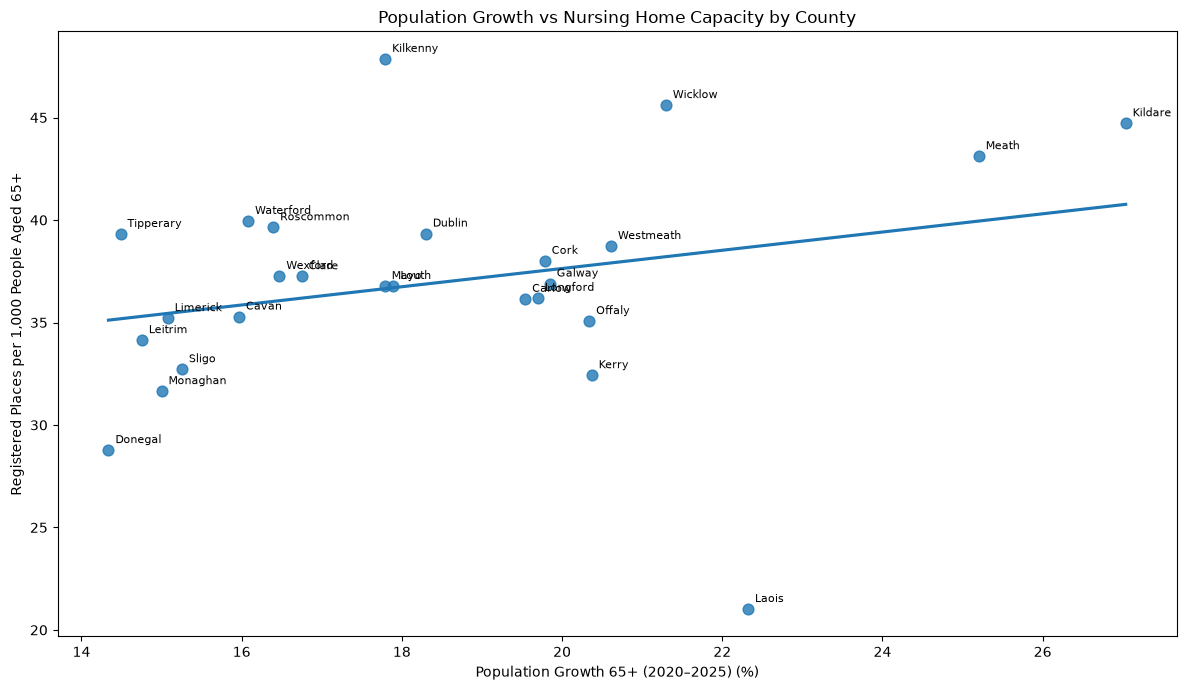

In [94]:
plt.figure(figsize=(12, 7))

sns.regplot(
    data=df_final_nursing_homes,
    x='percentage_growth',
    y='capacity_per_1000_older_people',
    ci=None,
    scatter_kws={'s': 60}
)

for _, row in df_final_nursing_homes.iterrows():
    plt.annotate(
        row['county'],
        (row['percentage_growth'], row['capacity_per_1000_older_people']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8
    )

plt.title('Population Growth vs Nursing Home Capacity by County')
plt.xlabel('Population Growth 65+ (2020–2025) (%)')
plt.ylabel('Registered Places per 1,000 People Aged 65+')

plt.tight_layout()
plt.show()